# IT5022 — Fundamentals of Machine Learning
## Notebook 03: Supervised Learning — Credit Risk Classification
**Project:** Real-World Credit Risk Scoring & Customer Financial Segmentation  
**Authors:** MSc Candidate Ginuka (MS26922898) & Team Member

---

### Objectives of this Notebook:
1. **Benchmark Baseline:** Fit a Dummy Classifier (Stratified & Most Frequent) as an empirical lower bound.
2. **Model 1 (Parametric Linear Baseline):** Regularized Logistic Regression:
   - 5-Fold Stratified Cross-Validation.
   - Hyperparameter optimization over $C$ and regularization penalties (L1 vs L2).
   - Cost-sensitive class weighting (`class_weight='balanced'`).
   - Decision threshold tuning via Precision-Recall curves.
3. **Model 2 (Non-linear Ensemble):** Random Forest Classifier:
   - 5-Fold Stratified Cross-Validation tuning `n_estimators`, `max_depth`, and `min_samples_leaf`.
   - Feature Importance analysis (Gini Impurity Reduction).
4. **Comparative Academic Evaluation:**
   - Accuracy, Precision, Recall, Specificity, F1-Score, Matthews Correlation Coefficient (MCC).
   - ROC-AUC and PR-AUC.
   - Side-by-side Confusion Matrices, ROC Curves, and PR Curves saved to `reports/figures/`.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

sys.path.append(os.path.abspath(".."))
from src.data_pipeline import CreditDomainFeatureEngineer, build_preprocessor, get_feature_lists
from src.evaluation_helpers import (
    evaluate_classifier, plot_confusion_matrices, plot_roc_pr_comparison
)

figures_dir = os.path.join("..", "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

print("Modules imported successfully.")


Modules imported successfully.


### 1. Ingest Data & Execute Leakage-Free Stratified Split


In [2]:
df = pd.read_csv(os.path.join("..", "dataset", "dataset.csv"))
X = df.drop(columns=['Credit_Score'])
y = (df['Credit_Score'] == 'Poor').astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Apply domain engineering
engineer = CreditDomainFeatureEngineer(drop_identifiers=True)
X_train_eng = engineer.transform(X_train_raw)
X_test_eng = engineer.transform(X_test_raw)

# Preprocessor
numeric_cols, categorical_cols = get_feature_lists(X_train_eng)
preprocessor = build_preprocessor(numeric_cols, categorical_cols)

X_train = preprocessor.fit_transform(X_train_eng)
X_test = preprocessor.transform(X_test_eng)

print(f"X_train Shape: {X_train.shape}, X_test Shape: {X_test.shape}")


X_train Shape: (6953, 39), X_test Shape: (1739, 39)


### 2. Empirical Baseline: Dummy Classifier


In [3]:
dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)
dummy_prob = dummy.predict_proba(X_test)[:, 1]

dummy_metrics = evaluate_classifier("Dummy Baseline (Most Frequent)", y_test, dummy_pred, dummy_prob)
pd.DataFrame([dummy_metrics])


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,MCC,ROC-AUC,PR-AUC,Brier Score
0,Dummy Baseline (Most Frequent),0.59632,0.59632,1.0,0.0,0.747118,0.0,0.5,0.59632,0.40368


### 3. Model 1: Regularized Logistic Regression (Parametric Baseline)
We optimize the inverse regularization parameter $C$ and penalty using 5-Fold Stratified Cross-Validation.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_lr = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'class_weight': ['balanced', None]
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr, cv=cv, scoring='f1', n_jobs=-1
)
grid_lr.fit(X_train, y_train)

best_lr = grid_lr.best_estimator_
print("Best Logistic Regression Parameters:", grid_lr.best_params_)
print(f"Best CV F1-Score: {grid_lr.best_score_:.4f}")

# Test set evaluation
lr_pred = best_lr.predict(X_test)
lr_prob = best_lr.predict_proba(X_test)[:, 1]

lr_metrics = evaluate_classifier("Tuned Logistic Regression", y_test, lr_pred, lr_prob)
pd.DataFrame([lr_metrics])


Best Logistic Regression Parameters: {'C': 0.1, 'class_weight': None, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV F1-Score: 0.8274


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,MCC,ROC-AUC,PR-AUC,Brier Score
0,Tuned Logistic Regression,0.794135,0.837811,0.811958,0.767806,0.824682,0.575941,0.858318,0.897558,0.147282


### 4. Decision Threshold Optimization for Logistic Regression
In credit scoring, False Negatives (granting credit to a high-risk customer who defaults) are significantly costlier than False Positives. We analyze the Precision-Recall curve to tune the decision threshold.


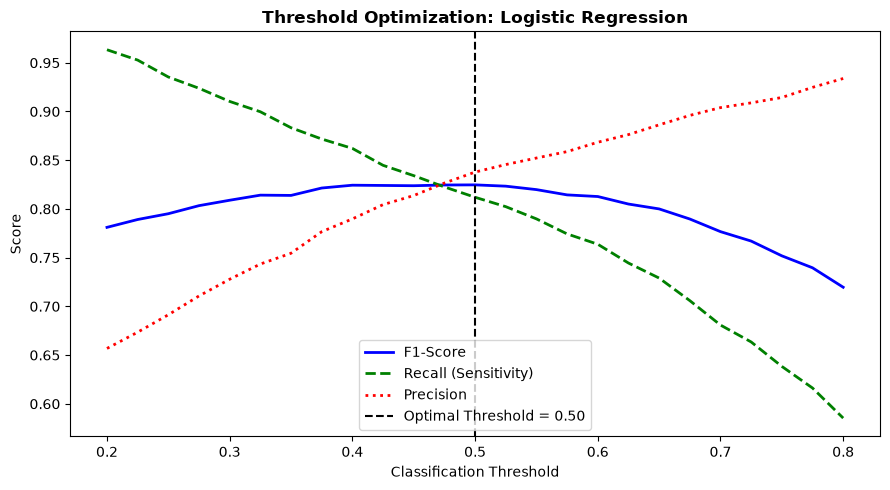

In [5]:
thresholds = np.linspace(0.2, 0.8, 25)
f1_scores = []
recalls = []
precisions = []

for t in thresholds:
    pred_t = (lr_prob >= t).astype(int)
    f1_scores.append(evaluate_classifier("LR", y_test, pred_t)["F1-Score"])
    recalls.append(evaluate_classifier("LR", y_test, pred_t)["Recall (Sensitivity)"])
    precisions.append(evaluate_classifier("LR", y_test, pred_t)["Precision"])

optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]

plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1_scores, 'b-', lw=2, label='F1-Score')
plt.plot(thresholds, recalls, 'g--', lw=2, label='Recall (Sensitivity)')
plt.plot(thresholds, precisions, 'r:', lw=2, label='Precision')
plt.axvline(optimal_threshold, color='k', linestyle='--', label=f'Optimal Threshold = {optimal_threshold:.2f}')
plt.title('Threshold Optimization: Logistic Regression', fontweight='bold')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '05_threshold_tuning_lr.png'), dpi=300)
plt.show()

# Evaluate at optimal threshold
lr_opt_pred = (lr_prob >= optimal_threshold).astype(int)
lr_opt_metrics = evaluate_classifier(f"Logistic Regression (t={optimal_threshold:.2f})", y_test, lr_opt_pred, lr_prob)


### 5. Model 2: Random Forest Classifier (Non-linear Ensemble)
We train an ensemble of decision trees using bootstrap aggregating (bagging) and random feature subspaces.


In [6]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [6, 10, 15],
    'min_samples_leaf': [2, 4],
    'class_weight': ['balanced', None]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf, cv=cv, scoring='f1', n_jobs=-1
)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
print("Best Random Forest Parameters:", grid_rf.best_params_)
print(f"Best CV F1-Score: {grid_rf.best_score_:.4f}")

# Test set evaluation
rf_pred = best_rf.predict(X_test)
rf_prob = best_rf.predict_proba(X_test)[:, 1]

rf_metrics = evaluate_classifier("Tuned Random Forest", y_test, rf_pred, rf_prob)
pd.DataFrame([rf_metrics])


Best Random Forest Parameters: {'class_weight': None, 'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 200}
Best CV F1-Score: 0.8534


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,MCC,ROC-AUC,PR-AUC,Brier Score
0,Tuned Random Forest,0.828637,0.876656,0.829315,0.827635,0.852329,0.650012,0.895636,0.927453,0.125237


### 6. Feature Importance Analysis (Random Forest)
We extract and plot the top 15 most important features based on Gini impurity reduction.


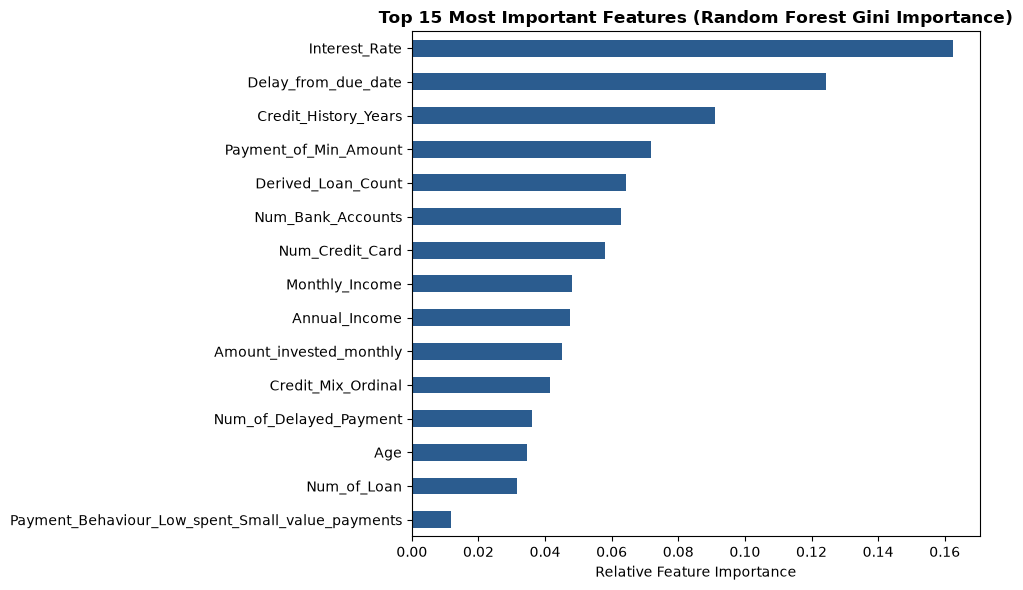

In [7]:
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = numeric_cols + cat_feature_names

importances = best_rf.feature_importances_
feat_importances = pd.Series(importances, index=all_features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feat_importances.head(15).plot(kind='barh', color='#2b5c8f')
plt.title('Top 15 Most Important Features (Random Forest Gini Importance)', fontweight='bold')
plt.xlabel('Relative Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '06_rf_feature_importances.png'), dpi=300)
plt.show()


### 7. Comparative Model Performance Summary
We synthesize all evaluation metrics into an academic comparison table and diagnostic plots.


In [8]:
results_df = pd.DataFrame([dummy_metrics, lr_metrics, lr_opt_metrics, rf_metrics])
results_df.set_index('Model', inplace=True)
print("=== COMPREHENSIVE PERFORMANCE EVALUATION TABLE ===")
display(results_df.round(4))


=== COMPREHENSIVE PERFORMANCE EVALUATION TABLE ===


,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,MCC,ROC-AUC,PR-AUC,Brier Score
Model,,,,,,,,,
Dummy Baseline (Most Frequent),0.5963,0.5963,1.0000,0.0000,0.7471,0.0000,0.5000,0.5963,0.4037
Tuned Logistic Regression,0.7941,0.8378,0.8120,0.7678,0.8247,0.5759,0.8583,0.8976,0.1473
Logistic Regression (t=0.50),0.7941,0.8378,0.8120,0.7678,0.8247,0.5759,0.8583,0.8976,0.1473
Tuned Random Forest,0.8286,0.8767,0.8293,0.8276,0.8523,0.6500,0.8956,0.9275,0.1252


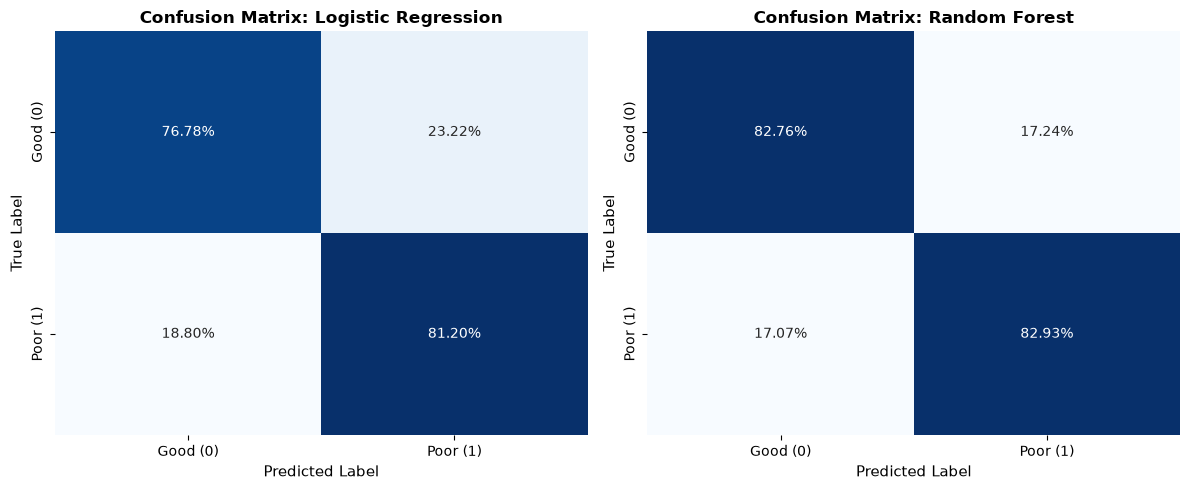

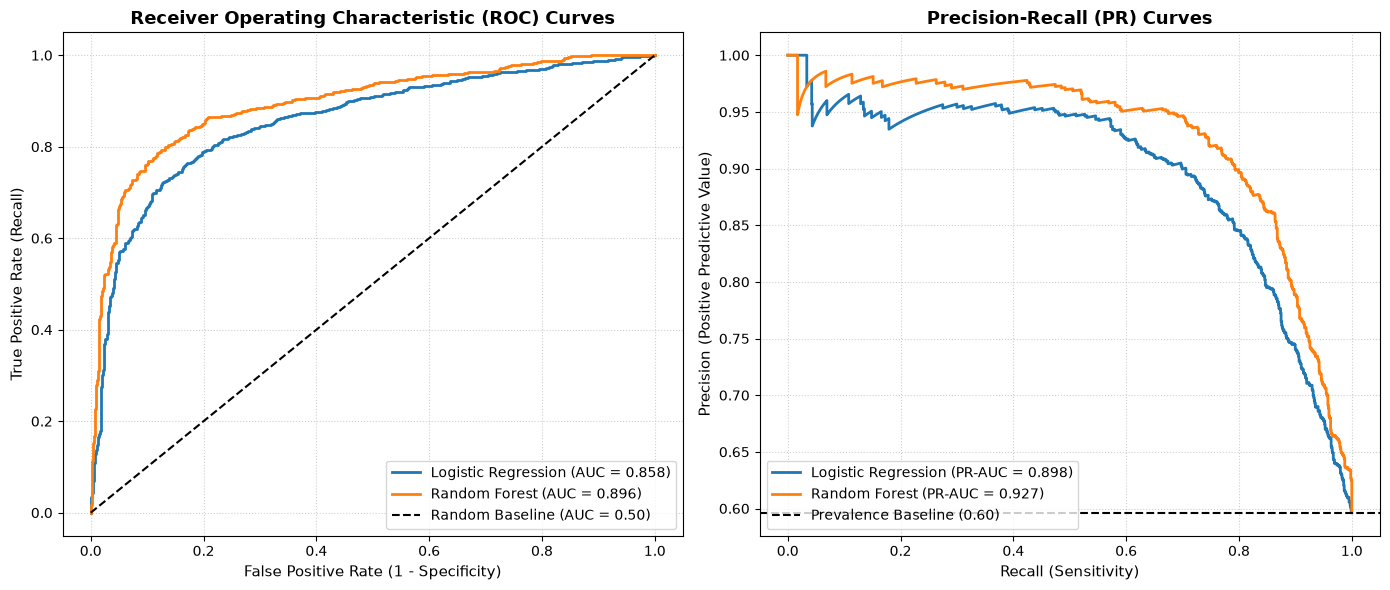

In [9]:
# 1. Confusion Matrices
models_dict = {
    'Logistic Regression': best_lr,
    'Random Forest': best_rf
}
plot_confusion_matrices(models_dict, X_test, y_test, save_path=os.path.join(figures_dir, '07_confusion_matrices.png'))

# 2. ROC and Precision-Recall Curves
prob_dict = {
    'Logistic Regression': lr_prob,
    'Random Forest': rf_prob
}
plot_roc_pr_comparison(prob_dict, y_test, save_path=os.path.join(figures_dir, '08_roc_pr_curves.png'))
